# TP3 — Réplicabilité et variabilité : analyse des résultats (partie 8)

Ce notebook **lit** le CSV produit par GitHub Actions et **ne produit aucune donnée**.
Avant chaque commit : *Restart Kernel and Run All Cells*.

Plan :
1. Chargement et inspection du CSV
2. Dans quelle mesure les facteurs impactent-ils la réponse ?
3. Arbre de décision (ML interprétable)
4. Recommandations pour obtenir un résultat stable
5. Explication des réponses des labs #1 et #2
6. Corrélation vs causalité

## 0. Configuration



In [28]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.model_selection import cross_val_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

CSV_PATH = "../results/results.csv"          
CAUSAL_CSV_PATH = "../results/causal.csv"   
ANSWER_COL = None                         
EXCLUDE = ["run", "run_id", "repetition_id", "timestamp", "date", "hostname",
           "commit", "job", "cmd", "command", "stdout", "output", "path", "file"]  
FACTORS = None                         

## 1. Chargement et inspection

In [4]:
df = pd.read_csv(CSV_PATH)
print(f"{len(df)} lignes, {df.shape[1]} colonnes")

if ANSWER_COL is None:
    for c in ["percentage", "percent", "pct", "answer", "result", "holds", "frequency", "ratio"]:
        if c in df.columns:
            ANSWER_COL = c
            break
    else:
        raise ValueError("Précise ANSWER_COL dans la cellule de configuration.")
df[ANSWER_COL] = pd.to_numeric(df[ANSWER_COL], errors="coerce")
df = df.dropna(subset=[ANSWER_COL]).copy()

if FACTORS is None:
    FACTORS = [c for c in df.columns
               if c != ANSWER_COL and c.lower() not in EXCLUDE and 1 < df[c].nunique() <= 50]
print("Réponse :", ANSWER_COL)
print("Facteurs :", FACTORS)
df.head()

480 lignes, 7 colonnes
Réponse : percentage
Facteurs : ['config_id', 'property', 'type', 'repetitions', 'seed']


,config_id,property,type,repetitions,seed,run,percentage
0,llm_c,AddAssociativity,Double,10000,1,1,74.21
1,llm_c,AddAssociativity,Double,10000,1,2,74.21
2,llm_c,AddAssociativity,Double,10000,1,3,74.21
3,llm_c,AddAssociativity,Double,10000,1,4,74.21
4,llm_c,AddAssociativity,Double,10000,1,5,74.21


In [5]:
# Valeurs prises par chaque facteur (une colonne constante n'est pas un facteur de variabilité)
pd.DataFrame({
    "nb valeurs": df[FACTORS].nunique(),
    "valeurs": [sorted(df[f].dropna().unique().tolist(), key=str)[:8] for f in FACTORS],
})

,nb valeurs,valeurs
config_id,32,"[llm_c, llm_python, r01, r02, r03, r04, r05, r06]"
property,3,"[AddAssociativity, Distributivity, MulAssociat..."
type,2,"[Double, Float]"
repetitions,3,"[100, 1000, 10000]"
seed,3,"[1, 123, 42]"


In [6]:
# Combien de configurations distinctes, et combien d'exécutions par configuration ?
runs_per_config = df.groupby(FACTORS, dropna=False).size()
print("Configurations distinctes :", len(runs_per_config))
print("Exécutions par configuration : min", runs_per_config.min(), "/ médiane", runs_per_config.median(), "/ max", runs_per_config.max())

Configurations distinctes : 96
Exécutions par configuration : min 5 / médiane 5.0 / max 5


## 2. Dans quelle mesure les facteurs impactent-ils la réponse ?

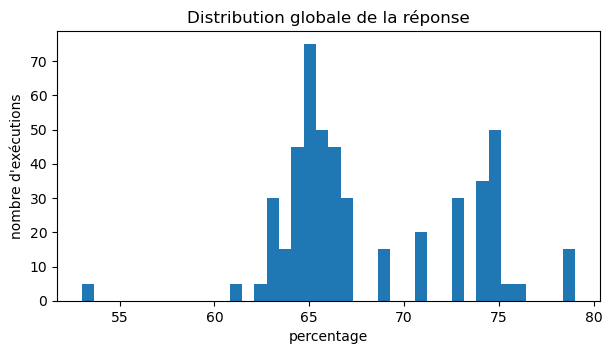

count    480.000000
mean      68.137292
std        4.827588
min       53.000000
25%       64.825000
50%       66.100000
75%       73.000000
max       79.000000
Name: percentage, dtype: float64


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df[ANSWER_COL], bins=40)
ax.set_xlabel(ANSWER_COL); ax.set_ylabel("nombre d'exécutions")
ax.set_title("Distribution globale de la réponse")
plt.show()
print(df[ANSWER_COL].describe())

### 2.1 Part de variance expliquée par chaque facteur (η²)

η² = variance *entre* les groupes d'un facteur / variance totale. Plus il est proche de 1, plus le facteur seul explique la réponse.
C'est une mesure marginale (un facteur à la fois) : elle ne capture pas les interactions, traitées avec l'arbre de décision.

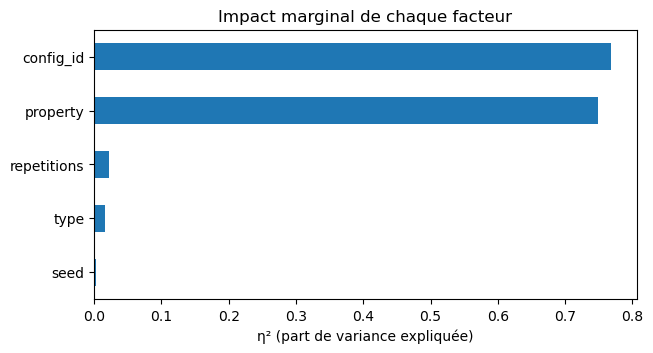

,eta²
config_id,0.768028
property,0.749551
repetitions,0.021722
type,0.015305
seed,0.002782


In [8]:
total_ss = ((df[ANSWER_COL] - df[ANSWER_COL].mean()) ** 2).sum()

def eta_squared(frame, factor):
    g = frame.groupby(factor, dropna=False)[ANSWER_COL]
    between = (g.count() * (g.mean() - frame[ANSWER_COL].mean()) ** 2).sum()
    return between / total_ss if total_ss > 0 else np.nan

eta = pd.Series({f: eta_squared(df, f) for f in FACTORS}).sort_values(ascending=False)
ax = eta.sort_values().plot.barh(figsize=(7, 0.4 * len(eta) + 1.5))
ax.set_xlabel("η² (part de variance expliquée)"); ax.set_title("Impact marginal de chaque facteur")
plt.show()
eta.to_frame("eta²")

### 2.2 Effet de chaque facteur sur la réponse (moyenne, écart-type, min, max par valeur)

In [9]:
for f in eta.index:
    print(f"\n=== {f} (η² = {eta[f]:.3f}) ===")
    display(df.groupby(f, dropna=False)[ANSWER_COL].agg(["count", "mean", "std", "min", "max"]).round(4))


=== config_id (η² = 0.768) ===


,count,mean,std,min,max
config_id,,,,,
llm_c,15,74.3100,0.1320,74.21,74.49
llm_python,15,74.3100,0.1320,74.21,74.49
r01,15,65.9667,0.6455,65.30,66.80
r02,15,74.2000,0.8824,73.00,74.90
r03,15,64.8667,0.3265,64.50,65.27
r04,15,66.1000,0.2535,65.80,66.40
r05,15,66.3333,2.5820,63.00,69.00
r06,15,66.0000,3.6839,63.00,71.00
r07,15,74.2000,0.8824,73.00,74.90



=== property (η² = 0.750) ===


,count,mean,std,min,max
property,,,,,
AddAssociativity,135,74.7837,1.6898,73.0,79.0
Distributivity,135,64.9733,3.3599,53.0,74.0
MulAssociativity,210,65.8986,2.0758,63.0,71.0



=== repetitions (η² = 0.022) ===


,count,mean,std,min,max
repetitions,,,,,
100,165,68.6667,5.9247,53.00,79.00
1000,180,68.5000,4.1494,62.10,75.20
10000,135,67.0067,3.9420,64.05,74.49



=== type (η² = 0.015) ===


,count,mean,std,min,max
type,,,,,
Double,225,68.7724,4.7044,61.0,79.0
Float,255,67.5769,4.8745,53.0,79.0



=== seed (η² = 0.003) ===


,count,mean,std,min,max
seed,,,,,
1,160,67.9416,4.8224,61.0,79.0
42,160,67.9738,5.0412,53.0,75.2
123,160,68.4966,4.6202,63.0,79.0


TypeError: Axes.boxplot() got an unexpected keyword argument 'tick_labels'

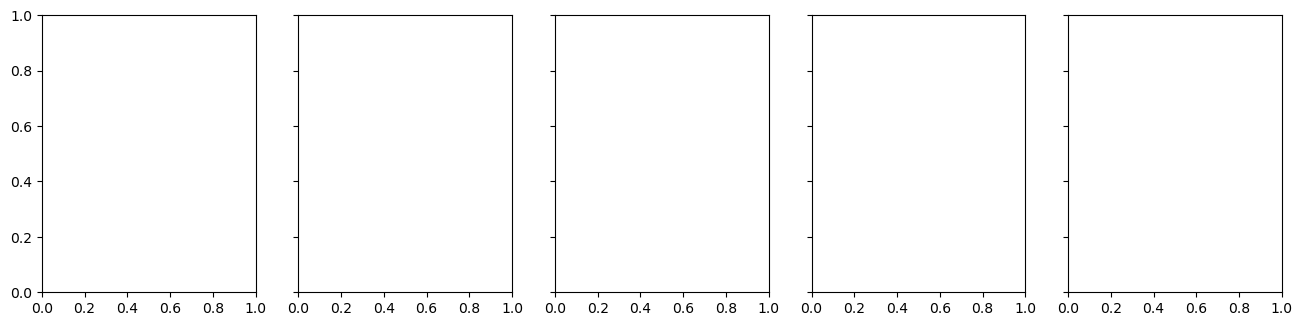

In [18]:
top = list(eta.index[:6])
n = len(top)
fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.6), sharey=True, squeeze=False)
for ax, f in zip(axes[0], top):
    groups = [g[ANSWER_COL].values for _, g in df.groupby(f, dropna=False)]
    labels = [str(k) for k, _ in df.groupby(f, dropna=False)]
    ax.boxplot(groups, tick_labels=labels)
    ax.set_title(f); ax.tick_params(axis="x", rotation=60)
axes[0][0].set_ylabel(ANSWER_COL)
plt.tight_layout(); plt.show()

### 2.3 Bruit d'exécution vs effet des facteurs

Chaque configuration a été exécutée plusieurs fois (la réponse est aléatoire). Si l'écart-type *au sein* d'une configuration
est petit devant l'écart *entre* configurations, les facteurs dominent ; sinon, c'est le hasard.

In [11]:
within = df.groupby(FACTORS, dropna=False)[ANSWER_COL].agg(["mean", "std", "count"])
print("Écart-type moyen au sein d'une configuration :", round(within["std"].mean(), 4))
print("Écart-type des moyennes entre configurations :", round(within["mean"].std(), 4))
print("Écart-type global                            :", round(df[ANSWER_COL].std(), 4))

Écart-type moyen au sein d'une configuration : 0.0
Écart-type des moyennes entre configurations : 4.8479
Écart-type global                            : 4.8276


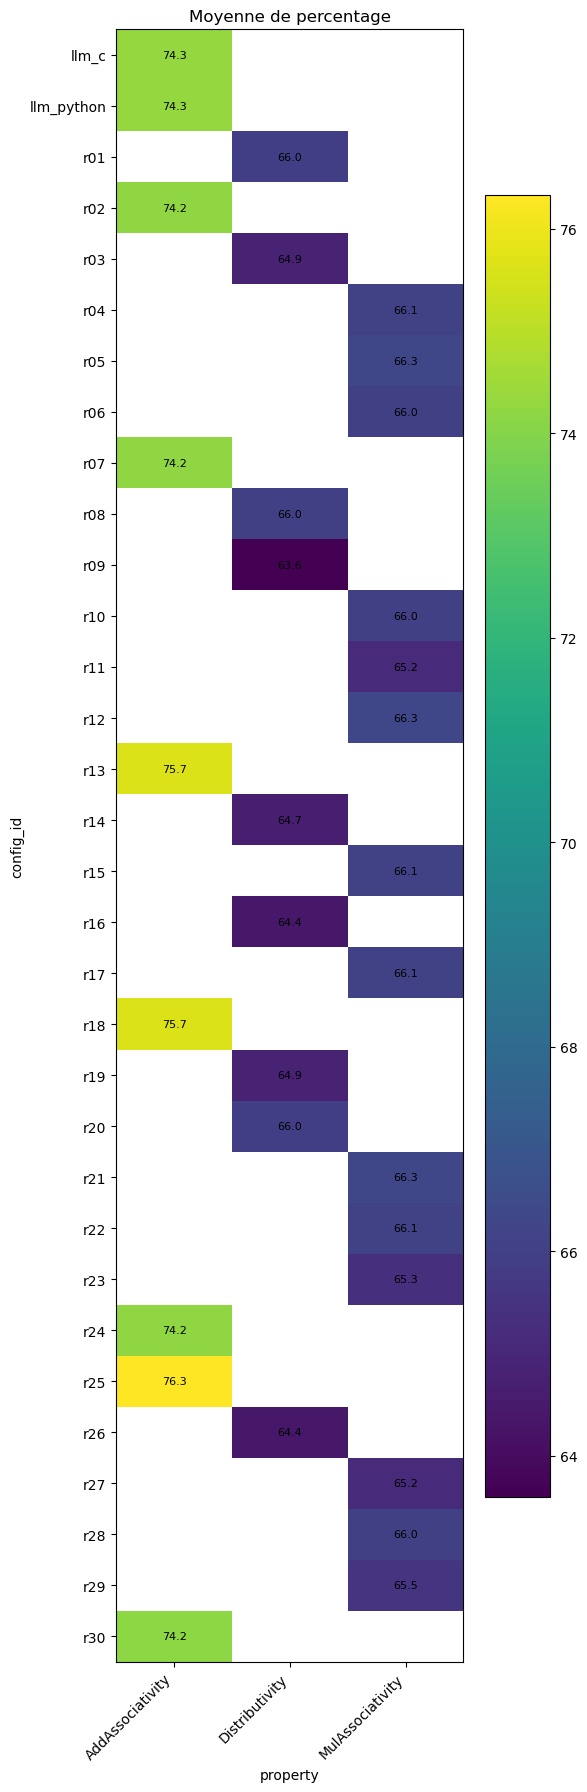

In [12]:
# Interactions : moyenne de la réponse pour les deux facteurs les plus influents
if len(eta) >= 2:
    a, b = eta.index[:2]
    pivot = df.pivot_table(index=a, columns=b, values=ANSWER_COL, aggfunc="mean")
    fig, ax = plt.subplots(figsize=(1.2 * max(pivot.shape[1], 3) + 2, 0.6 * pivot.shape[0] + 2))
    im = ax.imshow(pivot.values, aspect="auto")
    ax.set_xticks(range(pivot.shape[1])); ax.set_xticklabels([str(c) for c in pivot.columns], rotation=45, ha="right")
    ax.set_yticks(range(pivot.shape[0])); ax.set_yticklabels([str(i) for i in pivot.index])
    ax.set_xlabel(b); ax.set_ylabel(a); ax.set_title(f"Moyenne de {ANSWER_COL}")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im); plt.show()

## 3. Arbre de décision (ML interprétable)

On apprend un arbre de régression qui prédit la réponse à partir des facteurs. Les premières coupures désignent les facteurs
et les valeurs qui séparent le mieux les réponses. Les facteurs catégoriels sont encodés en one-hot.

In [13]:
X = pd.get_dummies(df[FACTORS].astype({c: str for c in FACTORS if df[c].dtype == object or df[c].dtype == bool}), dtype=float)
y = df[ANSWER_COL]

tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=max(5, len(df) // 100), random_state=0).fit(X, y)
r2_cv = cross_val_score(DecisionTreeRegressor(max_depth=4, min_samples_leaf=max(5, len(df) // 100), random_state=0),
                        X, y, cv=min(5, len(df)), scoring="r2")
print(f"R² sur les données : {tree.score(X, y):.3f}   |   R² en validation croisée : {r2_cv.mean():.3f}")
print()
print(export_text(tree, feature_names=list(X.columns), decimals=3))

R² sur les données : 0.837   |   R² en validation croisée : 0.733

|--- property_AddAssociativity <= 0.500
|   |--- property_Distributivity <= 0.500
|   |   |--- repetitions <= 5500.000
|   |   |   |--- seed <= 82.500
|   |   |   |   |--- value: [65.864]
|   |   |   |--- seed >  82.500
|   |   |   |   |--- value: [66.464]
|   |   |--- repetitions >  5500.000
|   |   |   |--- config_id_r29 <= 0.500
|   |   |   |   |--- value: [65.190]
|   |   |   |--- config_id_r29 >  0.500
|   |   |   |   |--- value: [65.500]
|   |--- property_Distributivity >  0.500
|   |   |--- seed <= 82.500
|   |   |   |--- config_id_r14 <= 0.500
|   |   |   |   |--- value: [65.086]
|   |   |   |--- config_id_r14 >  0.500
|   |   |   |   |--- value: [60.000]
|   |   |--- seed >  82.500
|   |   |   |--- config_id_r14 <= 0.500
|   |   |   |   |--- value: [64.863]
|   |   |   |--- config_id_r14 >  0.500
|   |   |   |   |--- value: [74.000]
|--- property_AddAssociativity >  0.500
|   |--- repetitions <= 550.000
|   |  

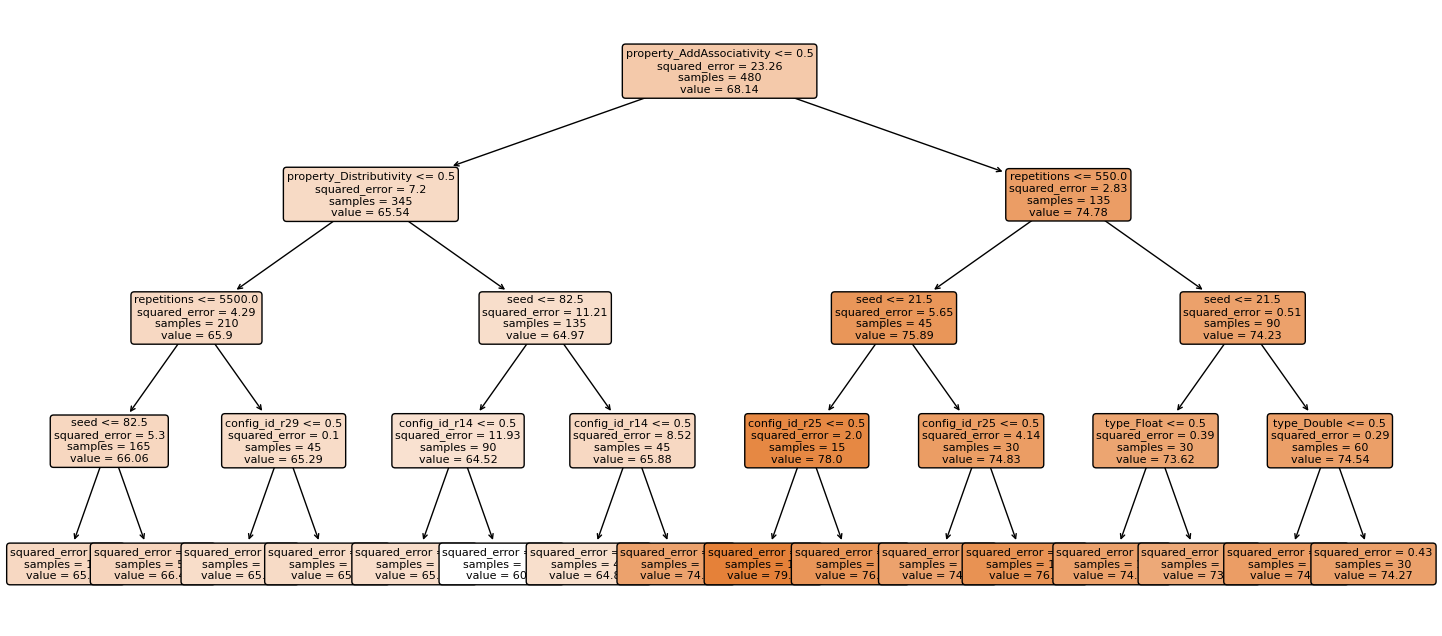

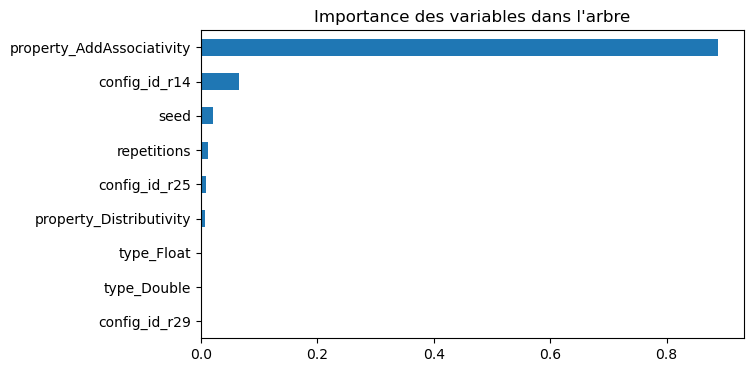

In [14]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(tree, feature_names=list(X.columns), filled=True, rounded=True, fontsize=8, ax=ax, precision=2)
plt.show()

imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
imp[imp > 0].head(15).sort_values().plot.barh(figsize=(7, 4), title="Importance des variables dans l'arbre")
plt.show()

## 4. Recommandations pour un résultat stable

Un résultat est *stable* si (a) il varie peu d'une exécution à l'autre pour une même configuration, et
(b) il varie peu d'une configuration à l'autre. On regarde, pour chaque valeur de facteur, le bruit d'exécution médian
et la dispersion des moyennes de configurations.

In [15]:
cfg = df.groupby(FACTORS, dropna=False)[ANSWER_COL].agg(mean="mean", std="std").reset_index()

rows = []
for f in FACTORS:
    for v, g in cfg.groupby(f, dropna=False):
        rows.append({"facteur": f, "valeur": v,
                     "bruit d'exécution (std médian)": g["std"].median(),
                     "dispersion entre configs (std des moyennes)": g["mean"].std(),
                     "moyenne": g["mean"].mean()})
stab = pd.DataFrame(rows)
stab.sort_values("bruit d'exécution (std médian)").head(15).round(4)

,facteur,valeur,bruit d'exécution (std médian),dispersion entre configs (std des moyennes),moyenne
0,config_id,llm_c,0.0,0.1562,74.3100
1,config_id,llm_python,0.0,0.1562,74.3100
2,config_id,r01,0.0,0.7638,65.9667
3,config_id,r02,0.0,1.0440,74.2000
4,config_id,r03,0.0,0.3863,64.8667
5,config_id,r04,0.0,0.3000,66.1000
6,config_id,r05,0.0,3.0551,66.3333
7,config_id,r06,0.0,4.3589,66.0000
8,config_id,r07,0.0,1.0440,74.2000
9,config_id,r08,0.0,5.0000,66.0000


In [17]:
# Les configurations les plus stables (écart-type le plus faible entre exécutions répétées)
cfg.sort_values("std").head(10).round(4)

,config_id,property,type,repetitions,seed,mean,std
88,r28,MulAssociativity,Float,100,42,63.00,0.0
89,r28,MulAssociativity,Float,100,123,71.00,0.0
90,r29,MulAssociativity,Double,10000,1,64.81,0.0
91,r29,MulAssociativity,Double,10000,42,65.78,0.0
92,r29,MulAssociativity,Double,10000,123,65.91,0.0
93,r30,AddAssociativity,Double,1000,1,74.30,0.0
94,r30,AddAssociativity,Double,1000,42,75.20,0.0
95,r30,AddAssociativity,Double,1000,123,73.00,0.0
0,llm_c,AddAssociativity,Double,10000,1,74.21,0.0
1,llm_c,AddAssociativity,Double,10000,42,74.23,0.0


In [16]:
# Y a-t-il des valeurs de facteurs pour lesquelles la réponse est (quasi) constante ?
const = cfg[cfg["std"].fillna(0) < 1e-9]
print(f"{len(const)} configuration(s) sur {len(cfg)} donnent exactement la même réponse à chaque exécution.")
const.head(10)

96 configuration(s) sur 96 donnent exactement la même réponse à chaque exécution.


,config_id,property,type,repetitions,seed,mean,std
0,llm_c,AddAssociativity,Double,10000,1,74.21,0.0
1,llm_c,AddAssociativity,Double,10000,42,74.23,0.0
2,llm_c,AddAssociativity,Double,10000,123,74.49,0.0
3,llm_python,AddAssociativity,Double,10000,1,74.21,0.0
4,llm_python,AddAssociativity,Double,10000,42,74.23,0.0
5,llm_python,AddAssociativity,Double,10000,123,74.49,0.0
6,r01,Distributivity,Double,1000,1,65.80,0.0
7,r01,Distributivity,Double,1000,42,66.80,0.0
8,r01,Distributivity,Double,1000,123,65.30,0.0
9,r02,AddAssociativity,Float,1000,1,73.00,0.0


## 5. Explication des réponses des labs #1 et #2

Retrouve dans le CSV les configurations qui correspondent à tes trois programmes (lab #1 en L1, LLM en L2, LLM en L1) :
renseigne pour chacun la valeur de chaque facteur (cf. matrice de comparaison, partie 1 ; modèle UVL, partie 4).

In [24]:
PROGRAMS = {
    "LLM en C (lab2)": {"config_id": "llm_c"},
    "LLM en Python (lab2)": {"config_id": "llm_python"},
}

MANUAL = {
    "mon programme (lab #1)": {"language": "c", "property": "AddAssociativity",
                               "type": "Double", "repetitions": 10_000_000,
                               "percentage": 92.39085},
}

def select(frame, conf):
    for k, v in conf.items():
        frame = frame[frame[k].astype(str) == str(v)]
    return frame

rows = []
for name, conf in PROGRAMS.items():
    sub = select(df, conf)
    rows.append({"programme": name,
                 "property": ", ".join(sub["property"].unique()),
                 "type": ", ".join(sub["type"].unique()),
                 "repetitions": ", ".join(map(str, sub["repetitions"].unique())),
                 "moyenne": sub[ANSWER_COL].mean(),
                 "min": sub[ANSWER_COL].min(), "max": sub[ANSWER_COL].max()})
for name, m in MANUAL.items():
    rows.append({"programme": name, "property": m["property"], "type": m["type"],
                 "repetitions": str(m["repetitions"]),
                 "moyenne": m["percentage"], "min": m["percentage"], "max": m["percentage"]})
display(pd.DataFrame(rows).round(2))

llm_mean = df[df["config_id"].str.startswith("llm")][ANSWER_COL].mean()
lab1 = MANUAL["mon programme (lab #1)"]["percentage"]
print(f"LLM (10 000 répétitions) : {llm_mean:.2f} %  |  lab #1 (10 000 000 répétitions) : {lab1:.2f} %")
print(f"Écart : {lab1 - llm_mean:.2f} points")
print(f"Écart-type dû au hasard à 10 000 000 répétitions : {100*np.sqrt(0.92*0.08/10_000_000):.3f} point")

,programme,property,type,repetitions,moyenne,min,max
0,LLM en C (lab2),AddAssociativity,Double,10000,74.31,74.21,74.49
1,LLM en Python (lab2),AddAssociativity,Double,10000,74.31,74.21,74.49
2,mon programme (lab #1),AddAssociativity,Double,10000000,92.39,92.39,92.39


LLM (10 000 répétitions) : 74.31 %  |  lab #1 (10 000 000 répétitions) : 92.39 %
Écart : 18.08 points
Écart-type dû au hasard à 10 000 000 répétitions : 0.009 point


Notre programme du lab #1 (C, double, 10 000 000 répétitions) donne 92,39 %, contre 74,3 % pour les programmes LLM (10 000 répétitions). Le nombre de répétitions n'explique pas cet écart de 18 points : à 10 000 000 répétitions, l'erreur d'échantillonnage est d'environ 0,01 point. Un autre facteur est donc en cause. Ce facteur ne peut pas être le type (les deux utilisent des double) ni la propriété (les deux testent l'associativité de l'addition). Il porte sur la manière dont les nombres sont tirés : plage de valeurs, nombre de bits du générateur, ou conversion en flottant. Notre expérience contrôlée montre que cette manière de tirer change la réponse : 82,8 % avec des flottants uniformes de 53 bits dans [0, 1), 74,6 % avec le tirage de type rand()/RAND_MAX, et 100 % avec des valeurs exactes. Aucun de ces tirages ne reproduit 92,39 % : il reste à identifier ce que fait précisément le programme du lab #1.


## 6. Corrélation n'est pas causalité

Les sections 2 et 3 montrent des **associations** : les facteurs n'ont pas été tirés indépendamment (échantillon de configurations
contraint par le modèle UVL), donc un effet observé peut en cacher un autre (confusion). Un effet est **causal** si en ne changeant
*que* ce facteur, tout le reste égal, la réponse change.

### Effets qu'on peut expliquer causalement

Le candidat naturel est l'**arrondi flottant** : sur des réels, `(x+y)+z = x+(y+z)` est toujours vrai ; c'est la représentation
finie des nombres (mantisse de 24 bits en `float32`, 53 en `float64`) qui rend l'égalité fausse pour certains triplets.
Ce mécanisme prédit que : (1) l'égalité est vraie à 100 % en arithmétique exacte (entiers, fractions) ; (2) la fréquence dépend du
type flottant ; (3) à graine et triplets identiques, changer *seulement* le type change la réponse.

### Ce qu'il faut exécuter

Une **intervention** : même graine, mêmes triplets, un seul facteur qui change. C'est le rôle du script
`causal_experiment.py` (versionné, lancé par GitHub Actions, il écrit `results/causal.csv`). Le notebook ne fait que le lire.

,count,mean,std,min,max
number_type,,,,,
float32,30,74.5679,0.1381,74.239,74.782
float64,30,82.7814,0.1162,82.512,83.051
fraction,30,100.0000,0.0000,100.000,100.000
int,30,100.0000,0.0000,100.000,100.000


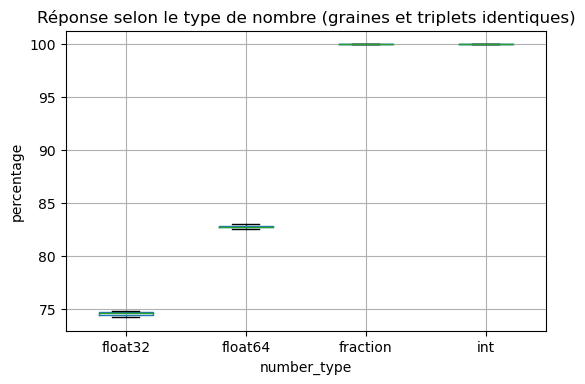

In [30]:
causal = pd.read_csv(CAUSAL_CSV_PATH)
display(causal.groupby("number_type")["percentage"].agg(["count", "mean", "std", "min", "max"]).round(4))

causal.boxplot(column="percentage", by="number_type", figsize=(6, 4))
plt.suptitle(""); plt.title("Réponse selon le type de nombre (graines et triplets identiques)")
plt.ylabel("percentage"); plt.show()

In [31]:
# Comparaison appariée : même graine, on ne change que le type de nombre
wide = causal.pivot_table(index="seed", columns="number_type", values="percentage")
print("Différence float32 - float64 (appariée par graine) :")
if {"float32", "float64"} <= set(wide.columns):
    d = wide["float32"] - wide["float64"]
    print(d.describe().round(4))
wide.head()

Différence float32 - float64 (appariée par graine) :
count    30.0000
mean     -8.2134
std       0.1678
min      -8.5070
25%      -8.3468
50%      -8.1945
75%      -8.1092
max      -7.8690
dtype: float64


number_type,float32,float64,fraction,int
seed,,,,
0,74.462,82.920,100.0,100.0
1,74.782,82.906,100.0,100.0
2,74.505,82.691,100.0,100.0
3,74.577,82.696,100.0,100.0
4,74.443,82.666,100.0,100.0


## Conclusion

Sur 480 exécutions (96 résultats distincts, 30 configurations échantillonnées et 2 programmes LLM), la fréquence mesurée varie de 53 % à 79 % (moyenne 68,1 %) : il n'existe pas de réponse unique, et la propriété testée domine (η² = 0,75 ; l'arbre de décision atteint un R² de 0,73 en validation croisée). L'associativité de l'addition donne environ 74 %, celle de la multiplication 65,3 % et la distributivité 64,6 % à 10 000 répétitions ; le type (Float/Double, η² = 0,015), le nombre de répétitions (0,022) et la graine (0,003) n'expliquent presque rien en moyenne. Les 5 exécutions d'une même configuration sont identiques (écart-type nul) : la graine étant fixée, le programme est déterministe et la seule variabilité vient du choix de la graine, dont l'effet diminue avec les répétitions (écart entre graines de 8,2 points à 100 répétitions, 1,5 à 1 000, 0,5 à 10 000, du même ordre de grandeur que l'erreur d'échantillonnage binomiale). Pour obtenir un résultat stable, il faut fixer la propriété, la graine, le type et la plateforme, et utiliser au moins 10 000 répétitions. Les programmes LLM du lab #2, en C et en Python, donnent les mêmes valeurs (74,21 %, 74,23 % et 74,49 % pour les graines 1, 42 et 123), alors que notre programme du lab #1 (C, double, 10 000 000 répétitions) donne 92,39 % : le nombre de répétitions ne l'explique pas (l'erreur d'échantillonnage est d'environ 0,01 point), ni le type ni la propriété, qui sont identiques. L'écart de 18 points vient donc d'un autre facteur, probablement la manière de tirer les nombres, qu'il reste à vérifier dans le code. L'expérience d'intervention (même graine, seul le type de nombre change) montre que l'arrondi flottant est une cause de la non-associativité : l'arithmétique exacte (entiers, fractions) donne 100 %, contre 82,8 % en float64 et 74,6 % en float32 (écart apparié de 8,2 points, écart-type de 0,17 sur 30 graines). Limites : un échantillon de 30 configurations (sans addition à 10 000 répétitions, cellule couverte seulement par les deux programmes LLM), seulement 3 graines par configuration et aucune intervention sur l'environnement (compilateur, architecture).